Carregamento de dados e importação de bibliotecas

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

data = pd.read_csv("diabetes.csv")

X = data.drop('Outcome', axis=1).values
y = data['Outcome'].values

scaler = MinMaxScaler()
X = scaler.fit_transform(X)

random_s = 42

### Part A: Clustering

1.

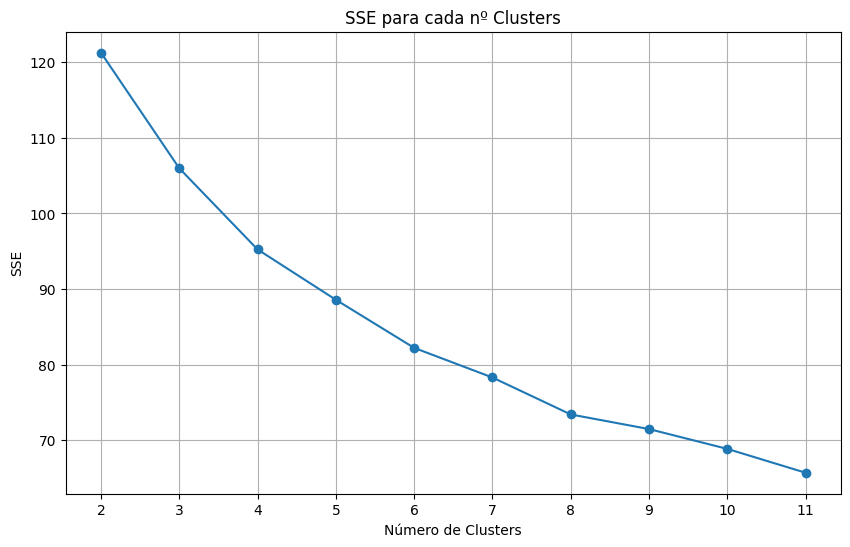

In [ ]:
k = [2,3,4,5,6,7,8,9,10,11]
SSE = []

for n in k:
    kmeans_algo = cluster.KMeans(n_clusters=n, random_state=random_s, max_iter=500)
    kmeans_model = kmeans_algo.fit(X)
    # adiciona o SSE deste numero de clusters à lista
    SSE.append(kmeans_model.inertia_)

plt.figure(figsize=(10,6))
plt.plot(k, SSE, marker='o')
plt.xlabel('Número de Clusters')
plt.ylabel('SSE')
plt.xticks(k)
plt.title('SSE para cada nº Clusters')
plt.grid(True)
plt.show()

2.

In [28]:
kmeans_algo = cluster.KMeans(n_clusters=6, random_state=random_s)
kmeans_model = kmeans_algo.fit(X)

#lista com o cluster atribuido a cada um
clusters = kmeans_model.labels_

#cria um dicionário com a class de cada cluster por maioria
cluster_to_class = {}
for c in np.unique(clusters):
    index_of_clust = np.where(clusters == c)
    majority_class = np.bincount(y[index_of_clust]).argmax()
    cluster_to_class[c] = majority_class

#cria a previsão para cada um com base no seu cluster
y_pred = np.array([cluster_to_class[c] for c in clusters])

conf_mat = confusion_matrix(y, y_pred)
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
f1 = f1_score(y, y_pred)

print("Confusion Matrix: \n", conf_mat)
print("Accuracy: ", accuracy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1-score: ", f1)

Confusion Matrix: 
 [[390 110]
 [119 149]]
Accuracy:  0.7018229166666666
Precision:  0.5752895752895753
Recall:  0.5559701492537313
F1-score:  0.5654648956356736


3.

In [ ]:
purity = {}

print("Cluster class counts:")
for c in np.unique(clusters):
    index_of_clust = np.where(clusters == c)[0]
    class_counts = np.bincount(y[index_of_clust])
    majority_class_count = class_counts.max()
    purity[c] = majority_class_count / class_counts.sum()
    print(f"Cluster {c}: {class_counts}")

print("\nCluster centers:")
for i, center in enumerate(kmeans_model.cluster_centers_):
    print(f"Cluster {i}: {center}")

# ordena os clusters pela pureza
sorted_clusters = sorted(purity.items(), key=lambda x: x[1], reverse=True)

print("\nMost discriminative clusters (highest purity): %d (%f), %d (%f) and %d (%f)" %(sorted_clusters[0][0], sorted_clusters[0][1], sorted_clusters[1][0], sorted_clusters[1][1], sorted_clusters[2][0], sorted_clusters[2][1]))

Cluster class counts:
Cluster 0: [61 73]
Cluster 1: [254  26]
Cluster 2: [43 26]
Cluster 3: [19 16]
Cluster 4: [74 51]
Cluster 5: [49 76]

Cluster centers:
Cluster 0: [0.11062335 0.75110628 0.61041106 0.34539424 0.24772415 0.55248348
 0.23297475 0.13544776]
Cluster 1: [0.1039916  0.4980079  0.54888759 0.23874459 0.06925025 0.4474026
 0.14793522 0.0697619 ]
Cluster 2: [0.35038363 0.67941155 0.65906391 0.05167618 0.00961044 0.43992311
 0.139024   0.5968599 ]
Cluster 3: [2.13445378e-01 5.91959799e-01 1.11022302e-16 1.52958153e-02
 0.00000000e+00 3.83095593e-01 1.32548493e-01 1.61904762e-01]
Cluster 4: [0.28329412 0.61837186 0.60445902 0.01664646 0.01088416 0.47396721
 0.14181725 0.196     ]
Cluster 5: [0.50164706 0.65266332 0.62806557 0.32       0.14266667 0.51087928
 0.19649872 0.3812    ]

Most discriminative clusters (highest purity): 1 (0.907143), 2 (0.623188) and 5 (0.608000)


### Part B: PCA

1.

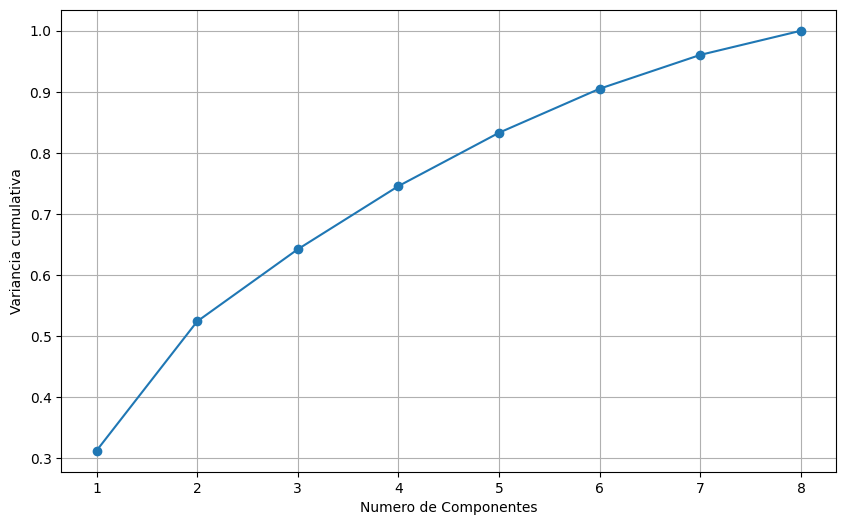

In [36]:
pca = PCA()
pca.fit(X)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10,6))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')
plt.xlabel('Numero de Componentes')
plt.ylabel('Variancia cumulativa')
plt.grid(True)
plt.show()

2.

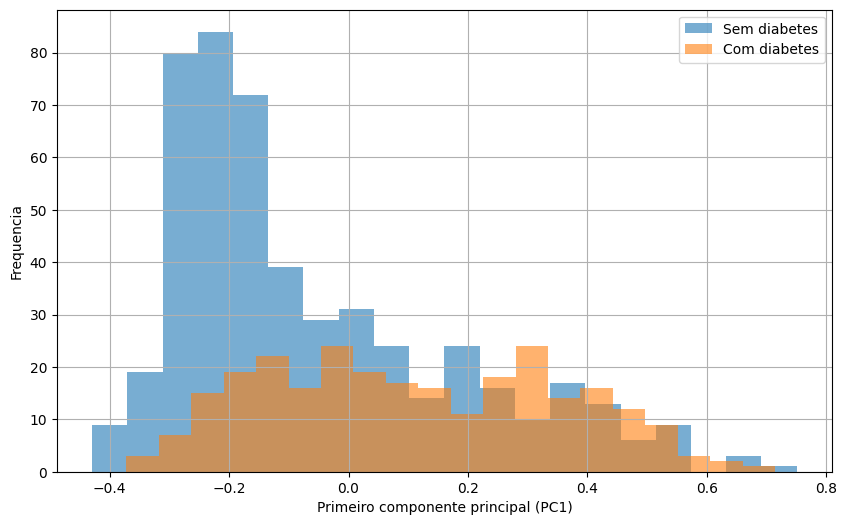

In [59]:
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))
plt.hist(X_pca[y == 0], bins=20, alpha=0.6, label="Sem diabetes")
plt.hist(X_pca[y == 1], bins=20, alpha=0.6, label="Com diabetes")
plt.xlabel('Primeiro componente principal (PC1)')
plt.ylabel('Frequencia')
plt.legend()
plt.grid(True)
plt.show()

3.

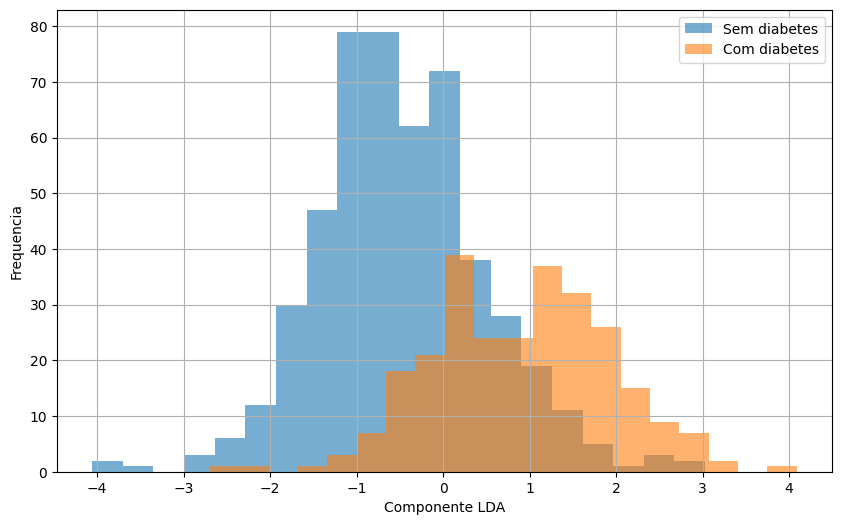

In [49]:
lda = LDA(n_components=1)
X_lda = lda.fit_transform(X, y)

plt.figure(figsize=(10, 6))
plt.hist(X_lda[y == 0], bins=20, alpha=0.6, label="Sem diabetes")
plt.hist(X_lda[y == 1], bins=20, alpha=0.6, label="Com diabetes")
plt.xlabel('Componente LDA')
plt.ylabel('Frequencia')
plt.legend()
plt.grid(True)
plt.show()